# MScFE 642 – Deep Learning for Finance
##  Group Work Project #2
### Tactical Asset Allocation using Deep Learning

## STEP 1 — DATA COLLECTION AND EXPLORATORY ANALYSIS

In [53]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

plt.style.use('seaborn-v0_8')

## Download ETF Data

In [54]:
tickers = ["SPY","TLT","SHY","GLD","DBO"]

start = "2010-01-01"
end = "2022-12-30"

data = yf.download(tickers,start=start,end=end)["Close"]

returns = data.pct_change().dropna()

data.head()

/tmp/ipykernel_3047/903658588.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers,start=start,end=end)["Close"]
[*********************100%***********************]  5 of 5 completed


Ticker,DBO,GLD,SHY,SPY,TLT
Date,,,,,
2010-01-04,23.807812,109.800003,66.209999,85.027946,56.359447
2010-01-05,24.028175,109.699997,66.289688,85.252991,56.723412
2010-01-06,24.324820,111.510002,66.297676,85.313057,55.964104
2010-01-07,24.155310,110.820000,66.281700,85.673187,56.058247
2010-01-08,24.273968,111.370003,66.345451,85.958290,56.033138


## Train / Validation / Test Split

In [55]:
train = returns[:'2015']
val = returns['2016':'2017']
test = returns['2018':]

print("Training set:",train.shape)
print("Validation set:",val.shape)
print("Test set:",test.shape)

Training set: (1509, 5)
Validation set: (503, 5)
Test set: (1258, 5)


## Summary Statistics

In [56]:
summary_stats = returns.describe()

summary_stats

Ticker,DBO,GLD,SHY,SPY,TLT
count,3270.000000,3270.000000,3270.000000,3270.000000,3270.000000
mean,0.000002,0.000181,0.000028,0.000510,0.000184
std,0.019141,0.009882,0.000694,0.011096,0.009514
min,-0.166453,-0.087808,-0.005088,-0.109423,-0.066683
25%,-0.009470,-0.004877,-0.000315,-0.003733,-0.005473
50%,0.001091,0.000429,0.000000,0.000655,0.000564
75%,0.010433,0.005386,0.000354,0.005750,0.005770
max,0.106227,0.049038,0.005453,0.090603,0.075196


## Price Evolution

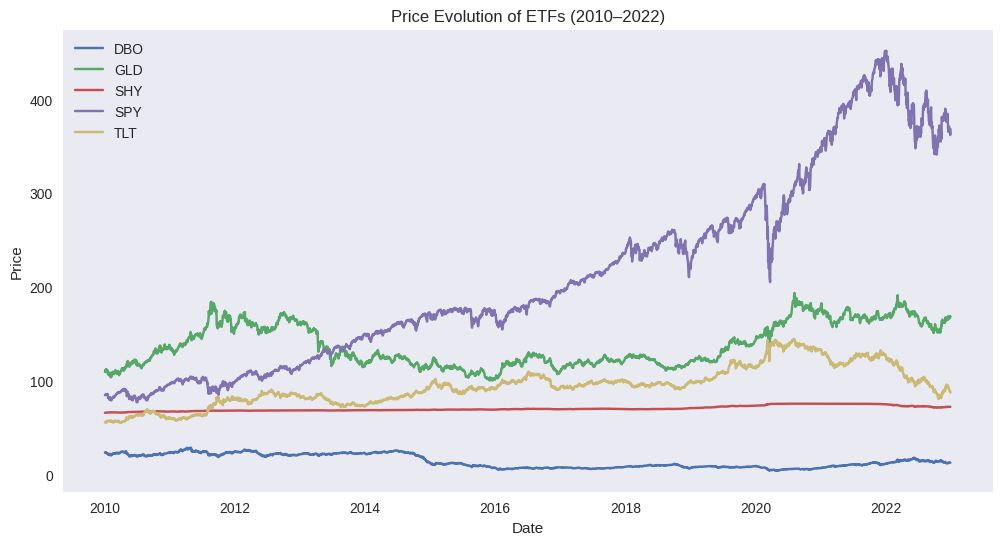

In [57]:
plt.figure(figsize=(12,6))

for col in data.columns:
    plt.plot(data.index,data[col],label=col)

plt.title("Price Evolution of ETFs (2010–2022)")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid()

plt.savefig("Price Evol of ETFS.png", dpi=300, bbox_inches="tight")
plt.show()

## Daily Returns Visualization

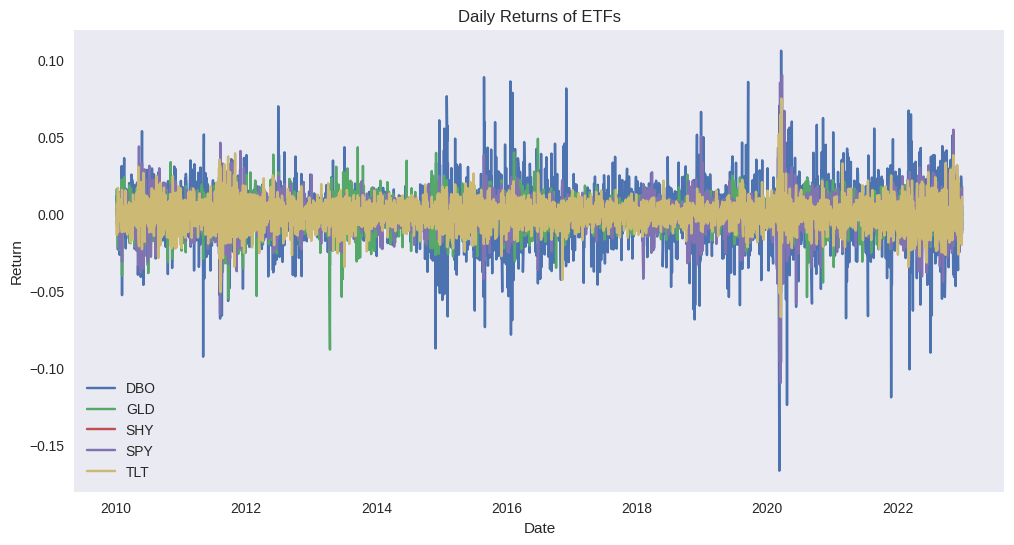

In [58]:
plt.figure(figsize=(12,6))

for col in returns.columns:
    plt.plot(returns.index,returns[col],label=col)

plt.title("Daily Returns of ETFs")
plt.xlabel("Date")
plt.ylabel("Return")

plt.legend()
plt.grid()

plt.savefig("Daily_Returns of ETFS.png", dpi=300, bbox_inches="tight")
plt.show()

## Distribution of Returns

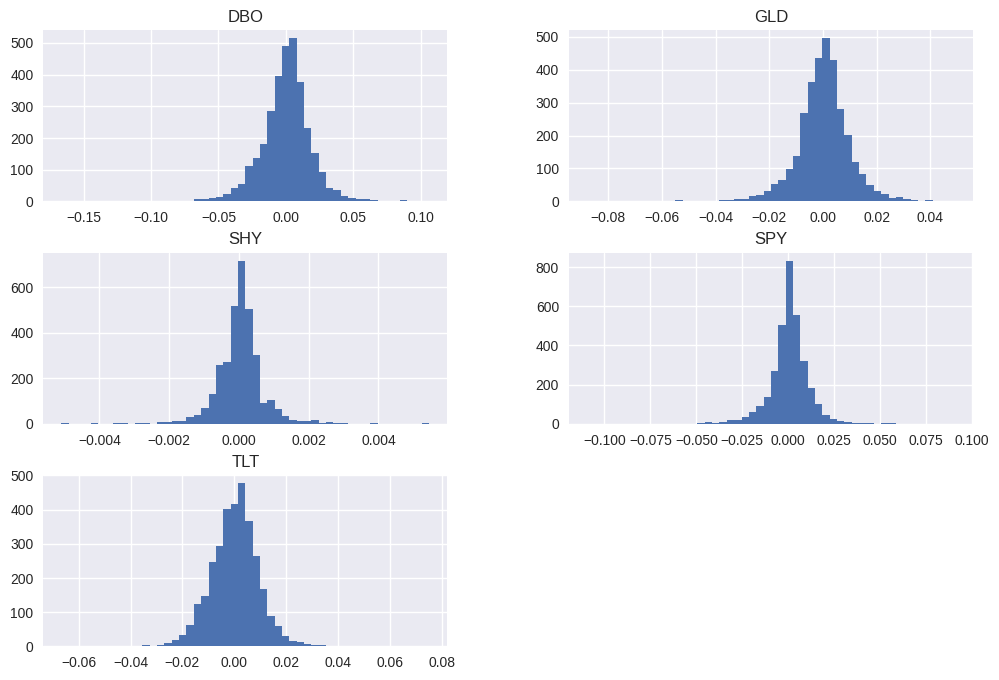

In [59]:
returns.hist(bins=50,figsize=(12,8))
plt.savefig("returns_dstrbtn.png", dpi=300, bbox_inches="tight")
plt.show()

## Correlation Matrix

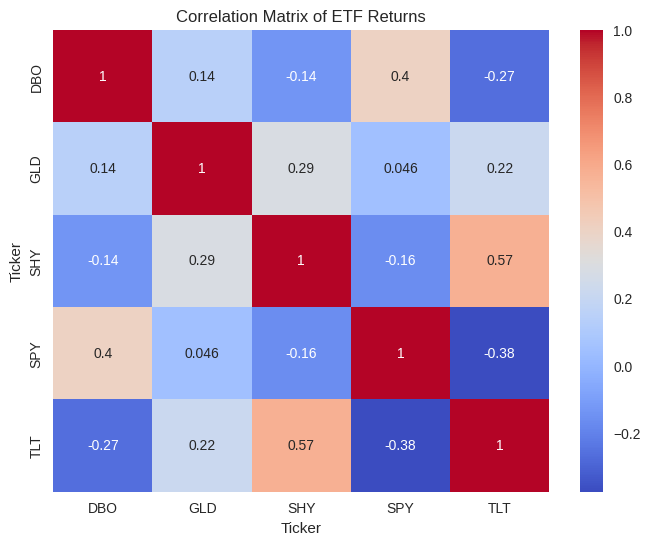

In [60]:
plt.figure(figsize=(8,6))

sns.heatmap(
    returns.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix of ETF Returns")
plt.savefig("corr_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## Covariance Matrix

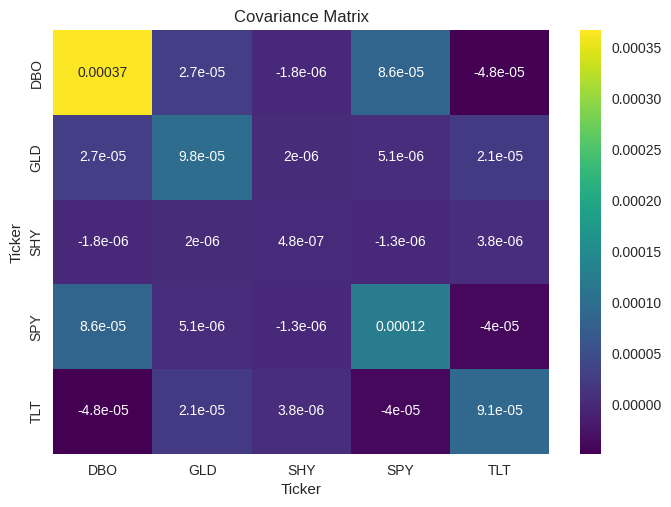

In [61]:
sns.heatmap(returns.cov(),annot=True,cmap="viridis")
plt.title("Covariance Matrix")
plt.savefig("cov_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## Rolling Volatility

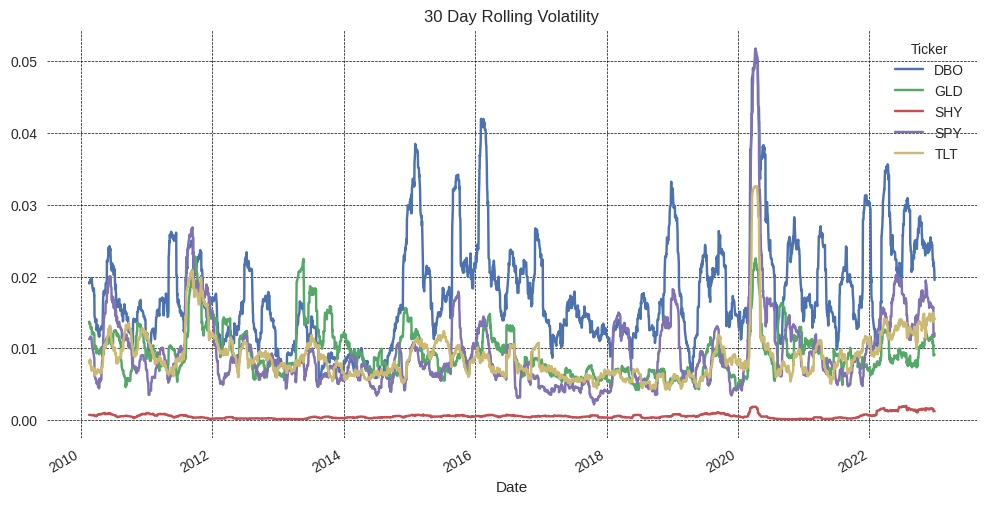

In [62]:
rolling_vol = returns.rolling(30).std()

ax = rolling_vol.plot(figsize=(12,6))

# Set background to white
ax.set_facecolor('white')
plt.gcf().set_facecolor('white')

# Add black gridlines
plt.grid(True, color='black', linestyle='--', linewidth=0.5)

plt.title("30 Day Rolling Volatility")

plt.savefig("rolling_volatility.png", dpi=300, bbox_inches="tight")
plt.show()

Stationarity Test (ADF)

In [63]:
def adf_test(series):

    result = adfuller(series)

    print("ADF:",result[0])
    print("p-value:",result[1])

for asset in returns.columns:

    print(asset)

    adf_test(returns[asset])

DBO
ADF: -60.10790119092413
p-value: 0.0
GLD
ADF: -57.72228125277754
p-value: 0.0
SHY
ADF: -11.865592228802853
p-value: 6.687448456555968e-22
SPY
ADF: -12.503103471963671
p-value: 2.778378607517287e-23
TLT
ADF: -10.501951765136214
p-value: 1.0782918566436277e-18


# STEP 2 — SINGLE OUTPUT LSTM MODELS

We forecast 25-day ahead returns.

In [64]:
horizon = 25
window = 30

## Dataset Construction

In [65]:
def create_dataset(series):

    X=[]
    y=[]

    for i in range(window,len(series)-horizon):

        X.append(series.iloc[i-window:i].values)
        y.append(series.iloc[i+horizon])

    return np.array(X),np.array(y)

## LSTM Model Architecture

In [66]:
def build_model():

    model = Sequential()

    model.add(LSTM(64,return_sequences=True))
    model.add(Dropout(0.2))

    model.add(LSTM(32))

    model.add(Dense(16,activation='relu'))

    model.add(Dense(1))

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

## Train Models

In [67]:
models={}

for asset in returns.columns:

    X,y=create_dataset(returns[[asset]])

    model=build_model()

    model.fit(
        X,y,
        epochs=20,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    models[asset]=model

## In-Sample Directional Accuracy

In [68]:
directional_accuracy_in = {}

for asset,model in models.items():

    X,y=create_dataset(returns[[asset]])

    pred=model.predict(X).flatten()

    acc=np.mean(np.sign(pred)==np.sign(y.flatten()))

    directional_accuracy_in[asset]=acc

directional_accuracy_in

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


{'DBO': np.float64(0.4640746500777605),
 'GLD': np.float64(0.4734059097978227),
 'SHY': np.float64(0.46531881804043546),
 'SPY': np.float64(0.5477449455676516),
 'TLT': np.float64(0.5250388802488336)}

## STEP 2 TRADING STRATEGY

Every 25 days:

• Long top 2 predicted ETFs
• Short bottom 2 predicted ETFs

## Portfolio Allocation

In [69]:
def allocation(pred):

    ranked = pred.sort_values()

    short = ranked.index[:2]
    long = ranked.index[-2:]

    weights = {}

    for a in long:
        weights[a] = 0.25

    for a in short:
        weights[a] = -0.25

    return weights

## Backtest Strategy

In [70]:
predicted_returns = pd.DataFrame(index=test.index,columns=returns.columns)

for asset,model in models.items():

    X_test,_ = create_dataset(test[[asset]])

    preds = model.predict(X_test).flatten()

    predicted_returns.loc[test.index[-len(preds):],asset] = preds

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


## Portfolio Returns

In [71]:
portfolio_returns=[]

for t in range(0,len(predicted_returns),25):

    preds=predicted_returns.iloc[t]

    weights=allocation(preds)

    window_returns=test.iloc[t:t+25]

    portfolio=(window_returns*pd.Series(weights)).sum(axis=1)

    portfolio_returns.append(portfolio)

portfolio_returns=pd.concat(portfolio_returns)

## Benchmark Portfolio

In [72]:
benchmark = test.mean(axis=1)

## Performance Metrics

In [73]:
def performance_metrics(r):

    annual_return=r.mean()*252
    volatility=r.std()*np.sqrt(252)
    sharpe=annual_return/volatility

    cumulative=(1+r).cumprod()

    drawdown=cumulative/cumulative.cummax()-1

    max_dd=drawdown.min()

    return annual_return,volatility,sharpe,max_dd

In [74]:
strategy_metrics = performance_metrics(portfolio_returns)
benchmark_metrics = performance_metrics(benchmark)

metrics_df = pd.DataFrame({
    "Metric": ["Annual Return", "Volatility", "Sharpe Ratio", "Maximum Drawdown"],
    "Tactical Strategy": strategy_metrics,
    "Benchmark": benchmark_metrics
})

metrics_df

,Metric,Tactical Strategy,Benchmark
0,Annual Return,-0.054691,0.064783
1,Volatility,0.107907,0.101209
2,Sharpe Ratio,-0.506831,0.640090
3,Maximum Drawdown,-0.401346,-0.167839


## Evaluate Strategy

In [75]:
performance_metrics(portfolio_returns)

performance_metrics(benchmark)

(np.float64(0.06478298039032569),
 np.float64(0.10120910113705542),
 np.float64(0.6400904628388886),
 -0.16783916471892235)

## Strategy vs Benchmark

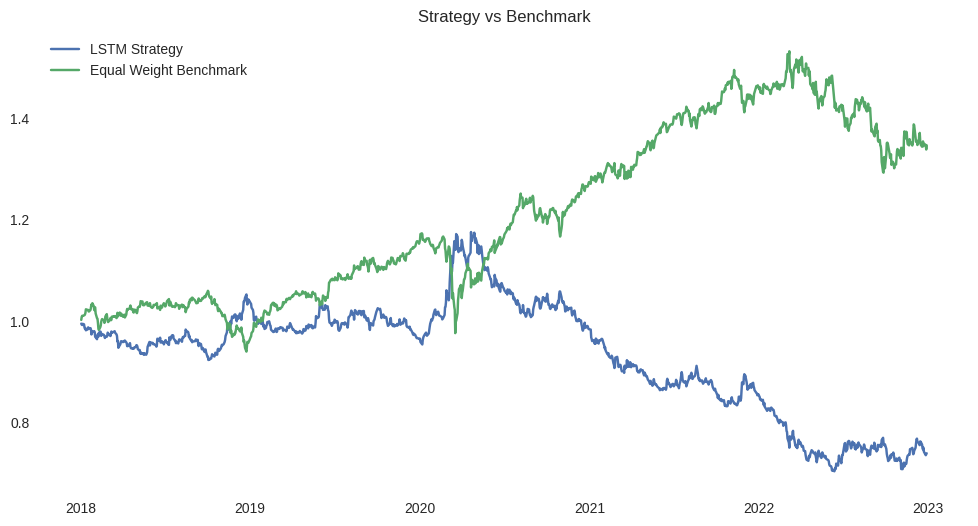

In [76]:
strategy_cum=(1+portfolio_returns).cumprod()

benchmark_cum=(1+benchmark).cumprod()

plt.figure(figsize=(12,6))
ax = plt.gca()
ax.set_facecolor('white')
plt.gcf().set_facecolor('white')

plt.plot(strategy_cum,label="LSTM Strategy")

plt.plot(benchmark_cum,label="Equal Weight Benchmark")

plt.legend()

plt.title("Strategy vs Benchmark")

plt.grid()

plt.savefig("strategy vs benchmark.png", dpi=300, bbox_inches="tight")
plt.show()

# STEP 3 — MULTI-OUTPUT LSTM

Predict all 5 ETFs simultaneously.

In [77]:
X=[]
y=[]

target = returns.shift(-horizon).dropna()

for i in range(window,len(returns)-horizon):

    X.append(returns.iloc[i-window:i].values)

    y.append(target.iloc[i].values)

X=np.array(X)
y=np.array(y)

## Multi-Output Model

In [78]:
model_multi = Sequential()

model_multi.add(LSTM(128,return_sequences=True))
model_multi.add(Dropout(0.2))

model_multi.add(LSTM(64))

model_multi.add(Dense(32,activation='relu'))

model_multi.add(Dense(5))

model_multi.compile(
    optimizer='adam',
    loss='mse'
)

model_multi.fit(
    X,y,
    epochs=25,
    batch_size=32,
    verbose=0
)

## Multi-Output Strategy

In [79]:
pred_multi = model_multi.predict(X)

pred_multi_df = pd.DataFrame(pred_multi,columns=returns.columns)

portfolio_returns_multi=[]

for t in range(0,len(pred_multi_df),25):

    preds=pred_multi_df.iloc[t]

    weights=allocation(preds)

    window_returns=returns.iloc[t:t+25]

    portfolio=(window_returns*pd.Series(weights)).sum(axis=1)

    portfolio_returns_multi.append(portfolio)

portfolio_returns_multi=pd.concat(portfolio_returns_multi)

101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step


## Compare Strategies

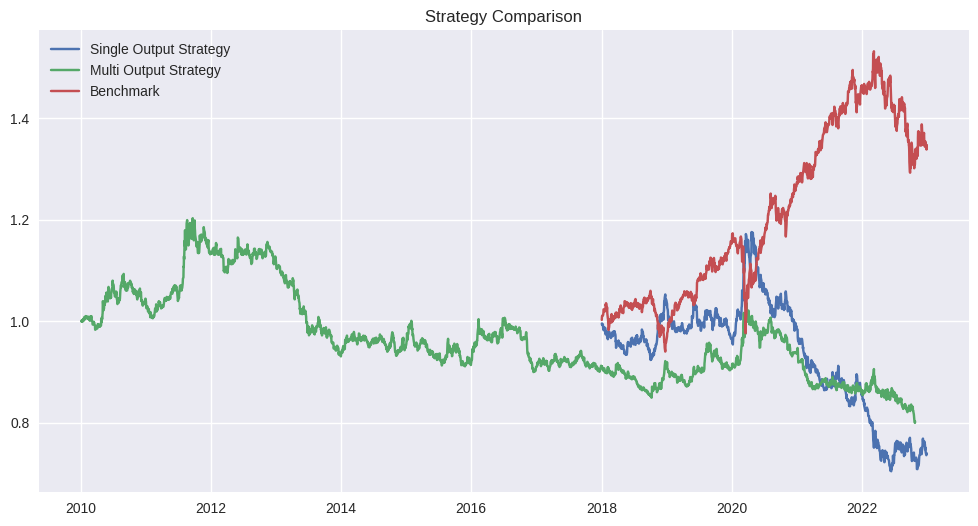

In [80]:
multi_cum=(1+portfolio_returns_multi).cumprod()

plt.figure(figsize=(12,6))
ax.set_facecolor('white')
plt.gcf().set_facecolor('white')

plt.plot(strategy_cum,label="Single Output Strategy")

plt.plot(multi_cum,label="Multi Output Strategy")

plt.plot(benchmark_cum,label="Benchmark")

plt.legend()

plt.title("Strategy Comparison")

plt.savefig("compare strategies.png", dpi=300, bbox_inches="tight")
plt.show()

In [81]:
strategy_metrics = performance_metrics(portfolio_returns)
benchmark_metrics = performance_metrics(benchmark)

metrics_df = pd.DataFrame({
    "Metric": ["Annual Return", "Volatility", "Sharpe Ratio", "Maximum Drawdown"],
    "Tactical Strategy": strategy_metrics,
    "Benchmark": benchmark_metrics
})

metrics_df

,Metric,Tactical Strategy,Benchmark
0,Annual Return,-0.054691,0.064783
1,Volatility,0.107907,0.101209
2,Sharpe Ratio,-0.506831,0.640090
3,Maximum Drawdown,-0.401346,-0.167839


## Prepare Multi-Asset Dataset

In [82]:
# Multi-asset dataset (inputs = all ETFs, outputs = all ETFs)

X_multi = []
y_multi = []

target = returns.shift(-horizon).dropna()

for i in range(window, len(returns) - horizon):

    X_multi.append(returns.iloc[i-window:i].values)   # shape: (window, 5)
    y_multi.append(target.iloc[i].values)             # shape: (5,)

X_multi = np.array(X_multi)
y_multi = np.array(y_multi)

print("X shape:", X_multi.shape)
print("y shape:", y_multi.shape)

X shape: (3215, 30, 5)
y shape: (3215, 5)


## Build Multi-Output LSTM Model

In [83]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model_multi = Sequential()

model_multi.add(LSTM(128, return_sequences=True))
model_multi.add(Dropout(0.2))

model_multi.add(LSTM(64))

model_multi.add(Dense(32, activation='relu'))

model_multi.add(Dense(5))  # 5 outputs (one per ETF)

model_multi.compile(
    optimizer='adam',
    loss='mse'
)

## Train Model

In [84]:
model_multi.fit(
    X_multi,
    y_multi,
    epochs=25,
    batch_size=32,
    verbose=0
)

## Generate Predictions

In [85]:
pred_multi = model_multi.predict(X_multi)

pred_multi_df = pd.DataFrame(
    pred_multi,
    columns=returns.columns
)

101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step


## Multi-Asset Strategy Backtest

In [86]:
portfolio_returns_multi = []

for t in range(0, len(pred_multi_df), 25):

    preds = pred_multi_df.iloc[t]

    weights = allocation(preds)

    window_returns = returns.iloc[t:t+25]

    portfolio = (window_returns * pd.Series(weights)).sum(axis=1)

    portfolio_returns_multi.append(portfolio)

portfolio_returns_multi = pd.concat(portfolio_returns_multi)

## Performance Metrics (Table 4)

In [87]:
# Compute metrics

benchmark_metrics = performance_metrics(benchmark)
single_metrics = performance_metrics(portfolio_returns)
multi_metrics = performance_metrics(portfolio_returns_multi)

In [88]:
table4 = pd.DataFrame({
    "Strategy": [
        "Benchmark Portfolio",
        "Independent Forecast Strategy",
        "Multi-Asset Forecast Strategy"
    ],
    "Sharpe Ratio": [
        round(benchmark_metrics[2], 2),
        round(single_metrics[2], 2),
        round(multi_metrics[2], 2)
    ],
    "Maximum Drawdown": [
        f"{benchmark_metrics[3]*100:.2f}%",
        f"{single_metrics[3]*100:.2f}%",
        f"{multi_metrics[3]*100:.2f}%"
    ]
})

table4

,Strategy,Sharpe Ratio,Maximum Drawdown
0,Benchmark Portfolio,0.64,-16.78%
1,Independent Forecast Strategy,-0.51,-40.13%
2,Multi-Asset Forecast Strategy,0.40,-14.02%


# **STEP 3: MULTI-OUTPUT LSTM**

In [89]:

# STEP 3: MULTI-OUTPUT LSTM

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
returns_scaled = pd.DataFrame(
    scaler.fit_transform(returns),
    index=returns.index,
    columns=returns.columns
)

window = 30
horizon = 25

def create_multi_dataset(data):
    X, y = [], []
    for i in range(window, len(data) - horizon):
        X.append(data.iloc[i-window:i].values)
        y.append(data.iloc[i+horizon].values)
    return np.array(X), np.array(y)

X, y = create_multi_dataset(returns_scaled)

# TRAIN / TEST SPLIT (NO LEAKAGE)

split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# BUILD MODEL

n_assets = returns.shape[1]

model = Sequential()
model.add(LSTM(64, return_sequences=True, input_shape=(window, n_assets)))
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dense(32, activation='relu'))
model.add(Dense(n_assets))  # Multi-output

model.compile(optimizer='adam', loss='mse')

# TRAIN MODEL

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# PREDICTIONS

y_pred = model.predict(X_test)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 0.7960 - val_loss: 2.1078
Epoch 2/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.7936 - val_loss: 2.1064
Epoch 3/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.7932 - val_loss: 2.1025
Epoch 4/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.7914 - val_loss: 2.1061
Epoch 5/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.7902 - val_loss: 2.1016
Epoch 6/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.7884 - val_loss: 2.1120
Epoch 7/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.7870 - val_loss: 2.1062
Epoch 8/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.7855 - val_loss: 2.1266
Epoch 9/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.7823 - val_loss: 2.1176
Epoch 10/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.7812 - val_loss: 2.1094
Epoch 11/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.7799 - val_loss: 2.1102
Epoch 12/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.7746 - val_l

## ETF LEVEL RESULTS

In [90]:
step3_accuracy = {}

for i, col in enumerate(returns.columns):
    acc = np.mean(np.sign(y_pred[:, i]) == np.sign(y_test[:, i]))
    step3_accuracy[col] = acc

print("\nSTEP 3 Directional Accuracy:")
for k,v in step3_accuracy.items():
    print(f"{k}: {v:.4f}")


STEP 3 Directional Accuracy:
DBO: 0.5334
GLD: 0.4914
SHY: 0.4899
SPY: 0.5257
TLT: 0.5008


# STEP 3 - BACKTEST

In [91]:
pred_index = returns.index[-len(y_test):]
pred_df = pd.DataFrame(y_pred, index=pred_index, columns=returns.columns)

test_returns = returns.loc[pred_index]

portfolio_s3 = []

for t in range(0, len(pred_df), 25):

    preds = pred_df.iloc[t]
    weights_dict = allocation(preds) # This returns a dictionary with 4 entries

    # Create a Series with all asset columns, initializing with 0 weights
    aligned_weights = pd.Series(0.0, index=returns.columns)

    # Update weights for the selected assets
    for asset, w in weights_dict.items():
        aligned_weights[asset] = w

    window_returns = test_returns.iloc[t:t+25]
    port = (window_returns * aligned_weights).sum(axis=1)

    portfolio_s3.append(port)

portfolio_s3 = pd.concat(portfolio_s3)

## BENCHMARK

In [92]:
benchmark = test_returns.mean(axis=1)

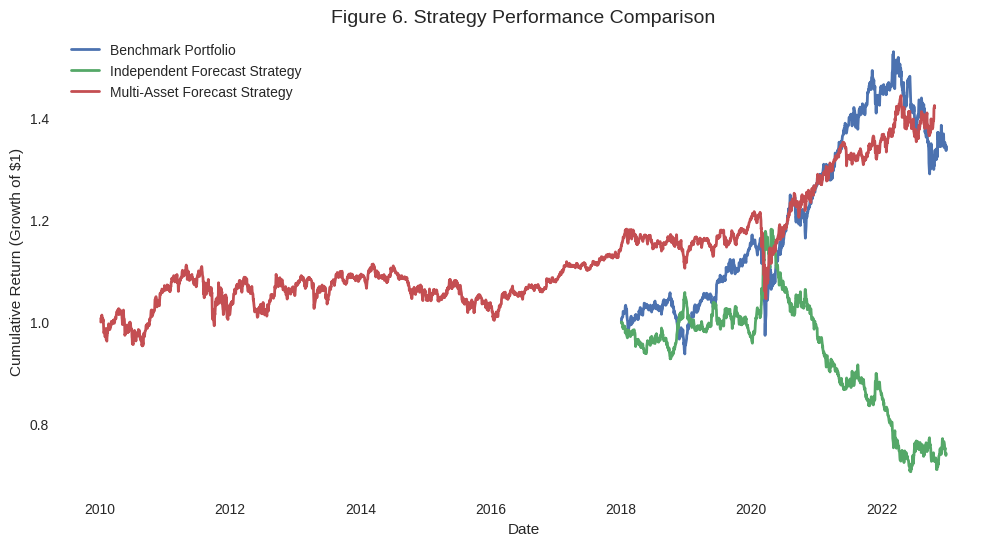

In [93]:
# Figure 6: Strategy Performance Comparison

# Ensure cumulative returns
multi_cum = (1 + portfolio_returns_multi).cumprod()

# Normalize to start at 1 (important for comparison)
strategy_cum = strategy_cum / strategy_cum.iloc[0]
benchmark_cum = benchmark_cum / benchmark_cum.iloc[0]
multi_cum = multi_cum / multi_cum.iloc[0]

# Plot
plt.figure(figsize=(12,6))

ax = plt.gca()
ax.set_facecolor('white')
plt.gcf().set_facecolor('white')

plt.plot(benchmark_cum, label="Benchmark Portfolio", linewidth=2)
plt.plot(strategy_cum, label="Independent Forecast Strategy", linewidth=2)
plt.plot(multi_cum, label="Multi-Asset Forecast Strategy", linewidth=2)

plt.title("Figure 6. Strategy Performance Comparison", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Cumulative Return (Growth of $1)")

plt.grid(True, linestyle='--', linewidth=0.5)
plt.legend()

plt.savefig("Figure_6_Strategy_Comparison.png", dpi=300, bbox_inches="tight")

plt.show()

## PERFORMANCE METRICS

In [94]:
def metrics(r):
    ret = (1+r).prod()-1
    sharpe = r.mean()/r.std()*np.sqrt(252)
    dd = (r.cumsum()-r.cumsum().cummax()).min()
    return ret, sharpe, dd

s2 = metrics(portfolio_returns)
s3 = metrics(portfolio_s3)
bh = metrics(benchmark)

print("\nPERFORMANCE RESULTS")
print(f"Step 2: Return={s2[0]*100:.2f}%, Sharpe={s2[1]:.2f}, DD={s2[2]*100:.2f}%")
print(f"Step 3: Return={s3[0]*100:.2f}%, Sharpe={s3[1]:.2f}, DD={s3[2]*100:.2f}%")
print(f"Benchmark: Return={bh[0]*100:.2f}%, Sharpe={bh[1]:.2f}, DD={bh[2]*100:.2f}%")


PERFORMANCE RESULTS
Step 2: Return=-26.06%, Sharpe=-0.51, DD=-50.08%
Step 3: Return=8.98%, Sharpe=0.39, DD=-11.44%
Benchmark: Return=18.70%, Sharpe=0.70, DD=-16.55%


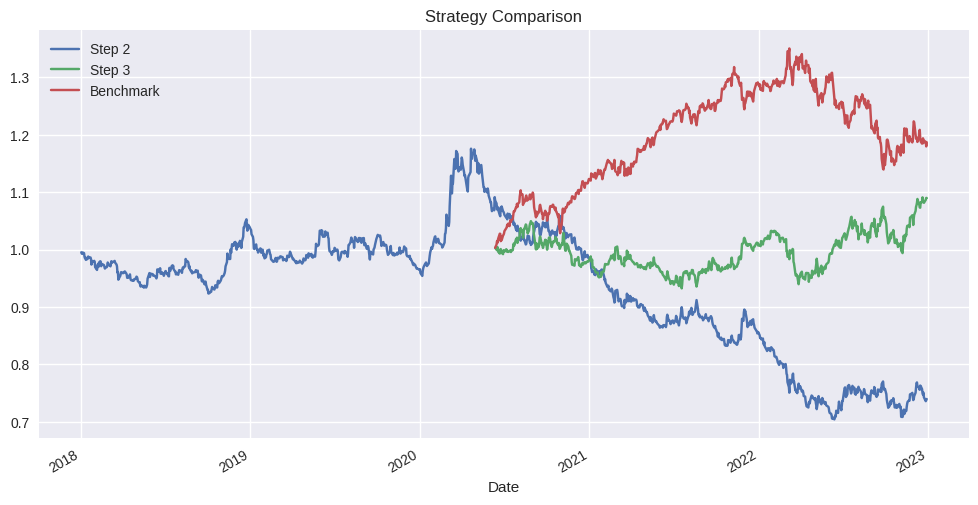

In [95]:
plt.figure(figsize=(12,6))
(1+portfolio_returns).cumprod().plot(label="Step 2")
(1+portfolio_s3).cumprod().plot(label="Step 3")
(1+benchmark).cumprod().plot(label="Benchmark")

plt.title("Strategy Comparison")
plt.legend()
plt.grid(True)
plt.savefig("Figure_6_Strategy_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()